# 04 · 内容管理项目实战


## 资料来源与当天目标

本篇对应 14 天规划的 **day04 项目实战**。第二篇完成课程查询与新增，第三篇完成参数校验、课程修改和计划维护；第四天把这些功能串起来，补上计划删除、上下移动、师资管理和整门课程删除，形成完整的内容管理操作流程。

| 资料 | 已核对的内容 |
|---|---|
| day04 / 资料 /《第2章 内容管理模块v3.1.docx》 | 第 9 节：实战环境、删除计划、计划排序、师资管理、删除课程；使用 day04 下载的新文件，正文与 day02 版本有少量差异，第 9 节任务相同 |
| day04 / 资料 /`实战资料.zip` | 独立的《第2章-内容管理 - 实战.pdf》，共 11 页；3 份 Vue 页面与替换说明；核对 PDF 全文并查看功能页面及接口页 |
| day04 / 代码 /`xuecheng-plus-project.zip` | 静态核对源码；与 day03 后端包 SHA256 完全相同，是实战起始代码，尚未实现本日 8 个业务接口 |
| day04 / 代码 / 前端代码每人都更换最新的 | 有完整前端压缩包；网盘提示下载内容超限，本篇未取得完整工程，不能据此声称已核对 API 封装和教师弹窗源码 |
| [网盘分享](https://pan.baidu.com/s/16iXzw7cFDk3FqG9DfPqbdg?pwd=6633) | 提取码 `6633`；Java 项目《学成在线》企业级开发实战 → 学成在线项目—资料 → day04 项目实战 |

**当天成果**：有子节点的章不能删除；删除小节同步清理计划媒资关系；计划只能与同级相邻节点交换顺序；教师增删改查受课程归属约束；删除草稿课程同时清理内容库关联记录。

> “讲义要求”“源码事实”“补充实现”分别标注。后文 Java 是放回课程工程后需要编译和测试的教学片段；本笔记没有运行服务、执行 SQL、启动 Gogs 或提交代码。6 张讲义原图嵌入 Notebook，支持离线阅读。


## 1. 实战任务：先把 8 个接口数清楚

实战 PDF 第 4 页明确写着“共 8 个接口”。这里的接口数量按具体请求操作计算：上移、下移各算一个，师资管理有四个。

| 模块 | 接口数 | 要交付的行为 |
|---|---:|---|
| 删除课程计划 | 1 | 检查章与小节关系，清理小节媒资关联 |
| 课程计划排序 | 2 | 上移、下移，同级交换，边界位置不变 |
| 师资管理 | 4 | 按课程查询、新增、修改、删除 |
| 删除课程 | 1 | 未提交课程的基本信息及关联记录整体删除 |
| 合计 | 8 | 接口测试、页面联调、交叉验收 |

建议按“共同契约与归属检查 → 计划删除 → 计划排序 → 师资 CRUD → 整课程删除 → 综合演示”开发。排序依赖前一天的计划树查询，删除课程又依赖对关联表的理解，所以先把单个节点和单个师资记录维护正确，再处理聚合删除。

**理解重点**：接口返回 200 只是其中一项结果。数据库关系是否清理、课程是否属于当前机构、刷新后顺序是否正确，同样属于交付内容。


## 2. 团队协作与 Gogs 环境

为什么实战需要远程仓库？因为每个人本地完成一个接口后，还要让其他人取得同一份代码并复现结果。团队验收针对合并后的工程，不能只演示个人电脑上的一个方法。

讲义给出的协作顺序：

1. 组长上传实战初始工程，组员克隆仓库。
2. 共同讨论需求、请求参数、响应与异常，再分配接口。
3. 每位成员至少完成一个接口，自己测试后提交。
4. 全体拉取完整代码，交叉测试，把 Bug 记入 Word 文档交组长汇总。
5. 各自修复并复测，提交修复；最后整体演示并作工作汇报。

讲义采用 Windows 版 `gogs_0.12.10_windows_amd64.zip`：由组长在自己的电脑部署 Gogs，安装前准备 `gogs_windows` 数据库；配置数据库连接、仓库目录、日志目录和管理员账号，再创建组织、仓库与组员账号。

| 配置项 | 讲义示例与理解 |
|---|---|
| 启动方式 | 在解压目录运行 `gogs.exe web`；这里仅记录操作，不实际启动 |
| 访问地址 | `http://group1.xuecheng.com:3000/` |
| 域名解析 | 组长与组员的 hosts 将 `group1.xuecheng.com` 指向组长电脑的实际 IP |
| 仓库示例 | `http://group1.xuecheng.com:3000/xuecheng-plus-group01/xuecheng-plus-project.git` |
| 可选环境 | 讲义允许安装不顺利时使用公网 Git 平台；不要求一定使用同一台虚拟机 |

实战 PDF 还要求配置自己的 Git 姓名和真实邮箱，组长收集账号并分配可写权限。**Git 提交身份、仓库登录账号、业务系统机构 ID 是三套不同概念**，不能混用。


## 3. 分工先定契约，再减少共用文件

讲义要求各成员创建自己的 Controller、Service 等文件，目的是减少多人编辑同一个文件的冲突。它不意味着相同 HTTP 接口可以重复注册。

例如，一个成员在 `TeachplanController` 定义 `DELETE /teachplan/{id}`，另一个成员在新 Controller 再定义相同映射，即使 Java 文件名不同，Spring 仍可能因重复请求映射无法启动。

| 分工内容 | 开发前必须约定 |
|---|---|
| 计划删除 | 子节点限制、媒资关联清理、失败提示 |
| 计划排序 | 兄弟范围、排序空洞、首尾处理 |
| 师资 CRUD | DTO 字段、记录 ID 的含义、课程归属 |
| 删除课程 | 允许状态、清理表、事务、重复请求 |
| 共用内容 | 错误模型、机构 ID 来源、Controller 路径、公共校验方法 |

**补充协作方案**：可以各自负责不同业务类，或由一位成员维护统一 Controller，其他人通过 Service 接口交付实现。共享的 DTO、错误结构、状态常量由明确负责人修改，再统一合并。

提交前核对“有没有重复映射、方法签名是否一致、是否漏了接口声明、Mapper 是否位于扫描路径”。即使每个文件单独看起来正确，合并后的依赖注入和 URL 注册也必须检查。


## 4. 前端实战补丁：知道换了哪些页面

`实战资料.zip` 的 `说明.txt` 要求把下面三个文件放到前端工程的同一目录，覆盖对应旧页面：

`project-xczx2-portal-vue-ts/src/module-organization/pages/course-manage`

| 文件 | 与本日接口的关系 |
|---|---|
| `course-add-step2-outline.vue` | 删除章 / 小节、上移、下移，并重新查询计划树 |
| `course-add-step3-teacher.vue` | 教师列表、添加 / 编辑弹窗入口、删除教师 |
| `course-list.vue` | 课程列表删除入口、按审核状态控制按钮 |

这是**复现时的替换说明**，本次写笔记没有覆盖用户的前端工程。实际替换前应保存现有修改，再确认使用的是当天配套前端版本。

已读补丁可以确认调用关系：

`deleteOutlineNode(teachPlanId)`、`moveUpSubmit(teachPlanId)`、`moveDownSubmit(teachPlanId)`；教师页调用 `getTeachers(courseBaseId)`、`deleteTeacher(courseBaseId, data.id)`；列表页调用 `removeCourse(row.id)`。

它们均从 `@/api/courses` 导入。**补丁包不含该 API 文件，也不含 `course-add-step3-teacher-dialog.vue`**，所以调用名和参数已核对，完整请求 URL、教师保存请求的真实方法仍要在实际工程中检查。

页面中还有视频绑定等入口；第四天不因此新增文件上传、视频处理或照片上传任务。当天要求明确写着“不用实现上传照片”。


## 5. 统一接口表：路径、动词与资料差异

下表按内容服务的实际入口写出完整路径。后端 `context-path` 为 `/content`，示例直连端口为 `63040`。

| 操作 | HTTP 方法 | 后端完整路径 | 成功结果 |
|---|---|---|---|
| 删除计划 | DELETE | `/content/teachplan/{teachplanId}` | 200，空 body |
| 上移计划 | POST | `/content/teachplan/moveup/{id}` | 本篇约定 200，空 body；讲义重点是移动效果 |
| 下移计划 | POST | `/content/teachplan/movedown/{id}` | 本篇约定 200，空 body；讲义重点是移动效果 |
| 查询师资 | GET | `/content/courseTeacher/list/{courseId}` | 师资对象数组，无记录时 `[]` |
| 新增师资 | POST | `/content/courseTeacher` | 保存后的对象，包含生成的 ID |
| 修改师资 | PUT | `/content/courseTeacher` | 修改后的对象 |
| 删除师资 | DELETE | `/content/courseTeacher/course/{courseId}/{teacherId}` | 200，空 body |
| 删除课程 | DELETE | `/content/course/{courseId}` | 200，空 body |

**资料差异与本篇处理**：

- 独立 PDF 第 10 页把修改教师写为 `post /courseTeacher`，day04 DOCX 第 9.4.2 节写为 `put /courseTeacher`。本篇按新版讲义使用 PUT，联调时核对完整前端 API；不能宣称补丁已证明 PUT。
- 两份资料均将删除教师误写为 `/ourseTeacher/course/75/26`。本篇校正为 `/courseTeacher/course/{courseId}/{teacherId}`，补齐字母 `c`；这是契约校正，起始包中没有完成接口可直接验证。
- 浏览器示例 `http://localhost:8601/api/content/...` 是前端代理入口。它不表示 Controller 要加 `/api/content`。

例如后端 Controller 使用 `@DeleteMapping("/teachplan/{teachplanId}")`，再叠加 `/content` 得到完整路径。若误写 `@DeleteMapping("/content/teachplan/{teachplanId}")`，会形成重复前缀。


## 6. 公共校验：由数据关系找到真正的课程

前端传一个计划 ID 或师资 ID，并不能证明用户有权修改它。课程归属保存在 `course_base.company_id`，因此必须先找到记录所属课程，再检查当前机构。

| 请求形式 | 正确校验链 |
|---|---|
| 只有计划 ID | `teachplanId → teachplan.courseId → course_base.companyId` |
| 有课程 ID 与教师记录 ID | 校验课程归属，再校验 `course_teacher.courseId == courseId` |
| 只有课程 ID | 查询基本信息并校验机构；删除时继续检查审核状态 |

讲义当前机构统一用 `1232141425L`；这是未接入认证阶段的临时值。接入认证后应从可信的登录身份取得，不能让表单传来的 `companyId` 决定权限。

下面是**补充的 Service 公共辅助方法**，供后续示例复用。方法应放进统一业务校验组件，或各 Service 中；相关 Mapper、PO、异常类需要正常导入和注入。

```java
private CourseBase requireOwnedCourse(Long companyId, Long courseId) {
    if (companyId == null || courseId == null) {
        throw new XueChengPlusException("机构和课程参数不能为空");
    }
    CourseBase course = courseBaseMapper.selectById(courseId);
    if (course == null || !companyId.equals(course.getCompanyId())) {
        throw new XueChengPlusException("课程不存在或无权操作");
    }
    return course;
}

private void requireDraft(CourseBase course) {
    if (!"202002".equals(course.getAuditStatus())) {
        throw new XueChengPlusException("课程已提交，不能删除");
    }
}

private Teachplan requirePlan(Long teachplanId) {
    if (teachplanId == null) {
        throw new XueChengPlusException("课程计划ID不能为空");
    }
    Teachplan plan = teachplanMapper.selectById(teachplanId);
    if (plan == null) {
        throw new XueChengPlusException("课程计划不存在");
    }
    return plan;
}
```

草稿值 `202002` 的依据是实战 `course-list.vue`：`auditStatus != '202002'` 时删除按钮禁用。最终要与实际数据库字典核对，不能只抄讲义中不一致的状态描述。

这里只给“删除计划 / 删除课程”使用 `requireDraft`。师资和排序是否也限制审核状态，讲义未完整规定，需另定产品规则，不能把补充策略说成原文要求。


## 7. 删除课程计划：章与小节为什么不同

课程计划是“章 → 小节”的结构。删除大章会影响整组小节，所以讲义要求有小节时拒绝删除；删除单个小节则必须同时去掉视频关联。

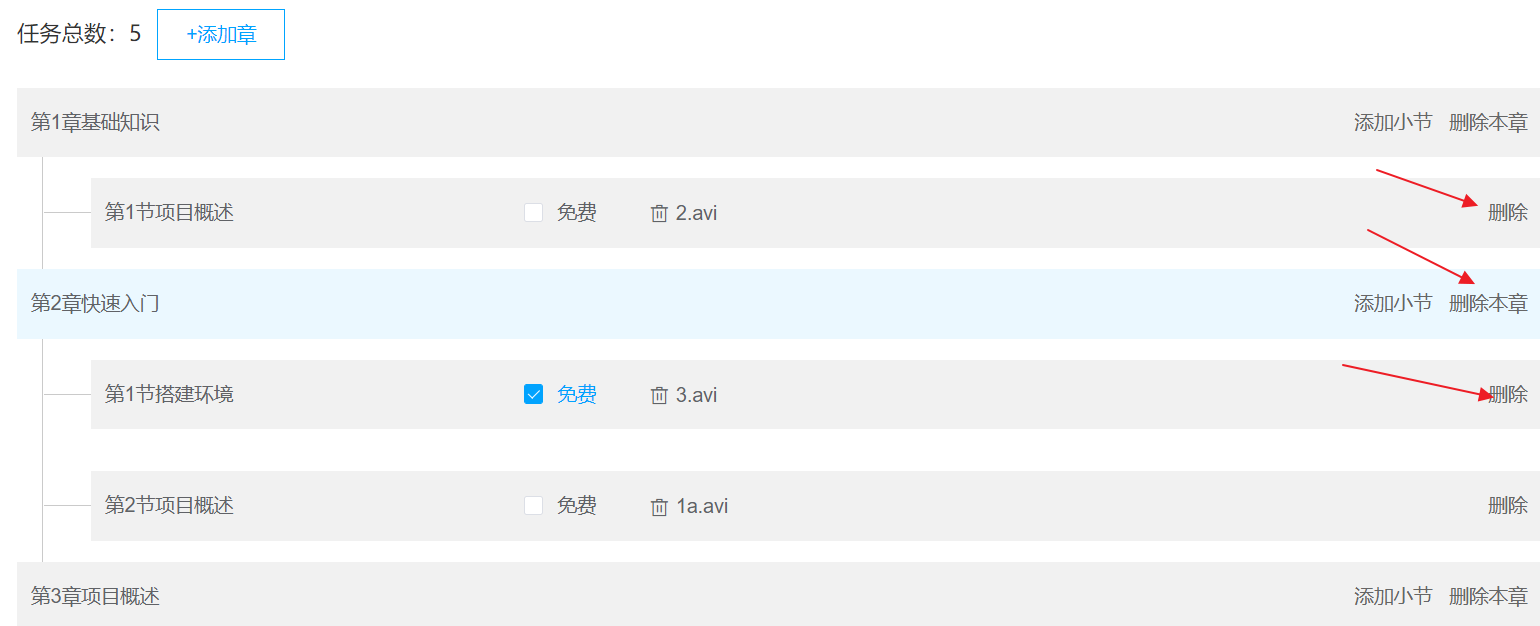

| 节点情况 | 讲义要求 |
|---|---|
| 课程尚未提交，大章下有小节 | 拒绝删除，保留原数据 |
| 课程尚未提交，大章下没有小节 | 可以删除该章 |
| 课程尚未提交，删除小节 | 删除小节，并删除 `teachplan_media` 关联 |
| 课程已提交 | 不允许删除课程计划 |

例如课程 75 的章 246 下有小节 247、248，直接删除 246 应失败；先逐一删除 247、248，确认章为空后才能删除 246。这与后文“整门课程删除”不同，后者在通过课程级检查后可以批量清理整棵计划树。

**补充检查**：不只判断 `grade == 1`；删除任何节点前查询实际孩子，遇到脏数据也应拒绝直接删父节点。孩子查询限定 `course_id` 和 `parentid`，避免跨课程数据串扰。


## 8. 删除计划的 Controller 与 Service

Controller 负责解析 ID 并传入当前机构；业务判断和两张表的修改应放在 Service 的同一事务中。

**补充实现片段**，在原 `TeachplanService` 增加 `deleteTeachplan(Long companyId, Long teachplanId)`，由实现类处理：

```java
@DeleteMapping("/teachplan/{teachplanId}")
public void deleteTeachplan(@PathVariable("teachplanId") Long teachplanId) {
    teachplanService.deleteTeachplan(1232141425L, teachplanId);
}
```

```java
@Transactional(rollbackFor = Exception.class)
public void deleteTeachplan(Long companyId, Long teachplanId) {
    Teachplan plan = requirePlan(teachplanId);
    CourseBase course = requireOwnedCourse(companyId, plan.getCourseId());
    requireDraft(course);

    Integer childCount = teachplanMapper.selectCount(
        new QueryWrapper<Teachplan>()
            .eq("course_id", plan.getCourseId())
            .eq("parentid", plan.getId())
    );
    if (childCount > 0) {
        throw new XueChengPlusException("课程计划信息还有子级信息，无法操作");
    }

    teachplanMediaMapper.delete(
        new QueryWrapper<TeachplanMedia>()
            .eq("course_id", plan.getCourseId())
            .eq("teachplan_id", plan.getId())
    );
    int deleted = teachplanMapper.delete(
        new QueryWrapper<Teachplan>()
            .eq("course_id", plan.getCourseId())
            .eq("id", plan.getId())
    );
    if (deleted != 1) {
        throw new XueChengPlusException("删除课程计划失败");
    }
}
```

MyBatis-Plus `3.4.1` 的 `BaseMapper.selectCount` 返回 `Integer`，这里按课程使用的版本写。查询构造器中使用数据库列名，如 `course_id`、`parentid`；不能误写 Java 属性 `courseId`。

小节没有绑定媒资时，关联删除影响 0 行是正常情况；计划主记录预期删除 1 行，若失败必须抛异常，让前面已删的关联一起回滚。片段对空章也清理可能存在的关联，以免保留异常关系数据。


## 9. 删除关系、异常契约与事务边界

`teachplan_media` 表记录“哪个计划使用哪个媒资”。删除这条关系，不代表删除共享视频文件。

| 对象 | 删除小节时的处理 |
|---|---|
| `teachplan` | 删除目标小节记录 |
| `teachplan_media` | 删除目标小节与媒资之间的绑定 |
| 媒资库文件记录 | 本接口不删除；可能被其他课程复用 |
| MinIO / 对象存储中的视频 | 本接口不删除；物理文件生命周期另行管理 |

讲义给出的“有子级不能删除”错误示例：

```json
{
  "errCode": "120409",
  "errMessage": "课程计划信息还有子级信息，无法操作"
}
```

**源码差异**：当前 `RestErrorResponse` 只有 `errMessage`，没有 `errCode`。前面的 Service 片段通过现有业务异常体系报错，不能自动产生这个 `120409` 字段。团队可以继续使用已有 `errMessage` 契约，或明确扩展错误模型和异常处理器后再返回业务码。

`120409` 是讲义的业务错误码，不能直接解释为 HTTP 409；失败 HTTP 状态需按异常处理契约约定。成功则按课程要求返回 **200 与空 body**。

事务需要从 Spring 代理调用的 Service 方法进入，多条删除使用同一事务资源。捕获异常后只打印日志并正常返回，会让调用者误以为成功；如果异常被吞掉，也可能导致事务提交。

**补充并发边界**：普通事务不自动保证“检查无孩子”之后不会有人新增小节。若需要严格保护，删除与新增计划要遵守同一套锁规则，例如先锁课程行，或锁父节点并让所有新增路径遵守；再在锁内重新检查课程状态和孩子。


## 10. 删除计划的 HTTP 验证与验收

下面的 ID 是讲义示例。复现时替换为自己的测试课程和计划，先查询树确认层级关系。

```http
### 先确认计划树和节点关系
GET http://localhost:63040/content/teachplan/75/tree-nodes

### 有小节的章：预期失败，不改变数据
DELETE http://localhost:63040/content/teachplan/246

### 小节：预期成功，同步清理媒资关系
DELETE http://localhost:63040/content/teachplan/247

### 删除后再次查询
GET http://localhost:63040/content/teachplan/75/tree-nodes
```

| 用例 | 必须确认的结果 |
|---|---|
| 删除有小节的章 | 有明确错误提示，章与小节都保留 |
| 删除空章 | 章消失，其他章与小节保留 |
| 删除绑定媒资的小节 | 小节及其 `teachplan_media` 记录消失，共享媒资保留 |
| 删除未绑定媒资的小节 | 关联 0 行不报错，计划正常删除 |
| 删除别的机构的计划 | 拒绝，任何关联都不改变 |
| 删除已提交课程中的计划 | 拒绝，数据库不改变 |
| 删除中途异常 | 已进行的关联删除回滚 |
| 重复删除同一计划 | 本篇片段返回“计划不存在”；也可约定幂等成功，但需全组一致 |

实战 Vue 的顺序是“确认弹窗 → 等待 `deleteOutlineNode` → `getList()`”。如果页面暂时隐藏节点，刷新后又出现，优先检查请求是否成功以及数据库是否真实删除；如果接口失败却无提示，再检查统一错误处理和页面空 `catch`。


## 11. 计划上下移：先确定“同级”的范围

讲义把上移定义为与上一个同级计划交换位置，下移定义为与下一个同级计划交换位置。页面操作看起来只是两个节点互换，后端必须先限定兄弟范围。

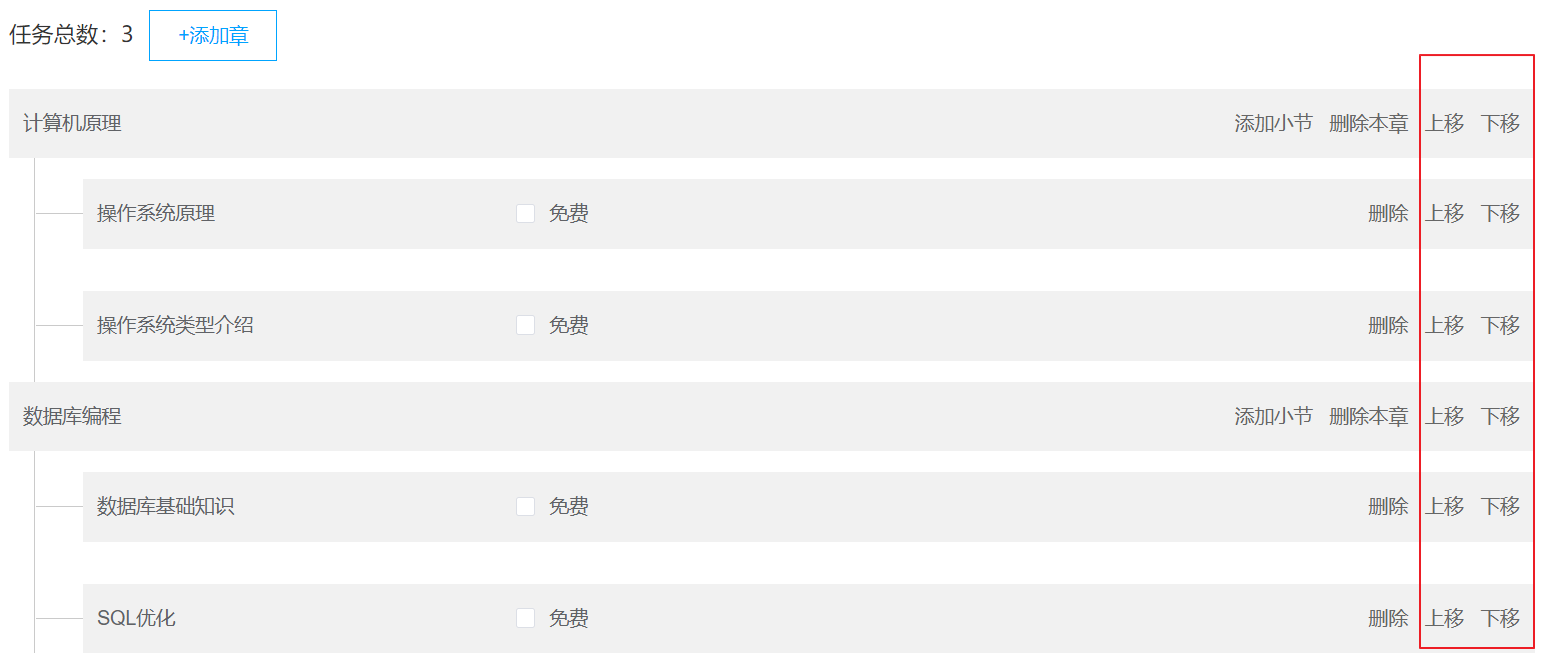

| 当前节点 | 可以交换的对象 |
|---|---|
| 课程 75 的一个大章 | 同课程、相同 `parentid` 的相邻大章 |
| 课程 75 的章 246 下的小节 | 同课程、同一章 246 下的相邻小节 |
| 最上面的兄弟 | 上移成功，顺序保持不变 |
| 最下面的兄弟 | 下移成功，顺序保持不变 |

**兄弟范围 = `courseId + parentid`**。顶层章的 `parentid` 通常为 0，但不同课程都可能使用 0，所以只按 `parentid = 0` 查会把其他课程的章混进来。只按 `grade = 2` 查也会混入同课程其他章的小节。

上移 / 下移仅改变 `orderby`，不改变 `course_id`、`parentid` 或 `grade`。把小节从一个章移到另一个章属于重新挂接节点，是另一个业务，不能借排序接口完成。


## 12. 找相邻节点：排序空洞与重复值

为什么不能按 `orderby - 1` 找上一条？第三篇已经说明删除会留下排序空洞，当前位置的前一个整数不一定对应实际记录。

| 兄弟数据 | 错误写法 | 正确判断 |
|---|---|---|
| A=1，B=3，C=8 | B 上移查 `orderby=2`，找不到就不动 | B 的实际前驱是 A |
| A=1，B=3，C=8 | B 下移直接把序号改成 4 | 应与 C 交换，得到 A=1、C=3、B=8 |
| A=3，B=3 | 交换两个 3 后声称排序成功 | 序号未改变，必须先处理重复值 |
| 其他章的小节也等于 3 | 仅按序号找到“邻居” | 限定当前课程和当前父节点 |

一种清楚的教学方案是先查全部兄弟：

```java
List<Teachplan> siblings = teachplanMapper.selectList(
    new QueryWrapper<Teachplan>()
        .eq("course_id", current.getCourseId())
        .eq("parentid", current.getParentid())
        .orderByAsc("orderby", "id")
);
```

在返回列表中找当前 ID 的索引 `i`：上移目标 `i-1`，下移目标 `i+1`；索引超出范围就正常返回。课程章 / 小节数量较少时，这比散落的特殊判断更容易理解和测试。

使用 `(orderby, id)` 排序让重复序号下的查询结果稳定，**不代表已经修好了重复排序数据**。本篇示例遇到空序号或重复值会拒绝移动，先规范化数据；规范化可在锁定兄弟集合后按稳定顺序重新分配 1、2、3……，但应单独约定和验证。

数据量较大时可用 SQL 查前驱 / 后继并 `LIMIT 1`，核心仍是相同兄弟范围和实际相邻关系，而不是直接计算一个整数。


## 13. 交换排序值：两次更新属于一次业务操作

下列为**补充的基础实现**，假设兄弟序号非空且互不重复，数据库未增加会阻碍直接交换的排序唯一约束。它解释查询与交换过程；严格并发版本见下一节。

在 Service 接口声明 `moveTeachplan(Long companyId, Long id, boolean up)`，Controller 的两个方法分别传 `true / false`。公共辅助方法沿用第 6 节。

```java
@Transactional(rollbackFor = Exception.class)
public void moveTeachplan(Long companyId, Long id, boolean up) {
    Teachplan current = requirePlan(id);
    requireOwnedCourse(companyId, current.getCourseId());
    List<Teachplan> siblings = teachplanMapper.selectList(
        new QueryWrapper<Teachplan>()
            .eq("course_id", current.getCourseId())
            .eq("parentid", current.getParentid())
            .orderByAsc("orderby", "id")
    );

    int index = -1;
    Set<Integer> orders = new HashSet<>();
    for (int i = 0; i < siblings.size(); i++) {
        Teachplan sibling = siblings.get(i);
        if (sibling.getOrderby() == null
                || !orders.add(sibling.getOrderby())) {
            throw new XueChengPlusException("同级排序数据异常，请先整理");
        }
        if (id.equals(sibling.getId())) {
            index = i;
        }
    }
    if (index < 0) {
        throw new XueChengPlusException("课程计划已发生变化");
    }
    int targetIndex = up ? index - 1 : index + 1;
    if (targetIndex < 0 || targetIndex >= siblings.size()) {
        return;
    }

    Teachplan a = siblings.get(index);
    Teachplan b = siblings.get(targetIndex);
    int countA = teachplanMapper.update(null,
        new UpdateWrapper<Teachplan>()
            .eq("id", a.getId())
            .eq("course_id", a.getCourseId())
            .eq("parentid", a.getParentid())
            .eq("orderby", a.getOrderby())
            .set("orderby", b.getOrderby())
    );
    int countB = teachplanMapper.update(null,
        new UpdateWrapper<Teachplan>()
            .eq("id", b.getId())
            .eq("course_id", b.getCourseId())
            .eq("parentid", b.getParentid())
            .eq("orderby", b.getOrderby())
            .set("orderby", a.getOrderby())
    );
    if (countA != 1 || countB != 1) {
        throw new XueChengPlusException("计划顺序已变化，请刷新后重试");
    }
}
```

代码只设置 `orderby`，不把旧实体的所有字段重新写回，减少覆盖名称、试看等并发修改的机会。更新条件带原序号，能发现一部分“读完以后值被别人改过”的冲突；失败抛异常，两个更新一起回滚。

所需类型为 `List`、`Set`、`HashSet`、`QueryWrapper`、`UpdateWrapper`、`Teachplan` 与业务异常；需在实现类正常导入。这不是当前代码包已经存在的方法，也未做 Java 编译验证。


## 14. 排序事务与并发：保证原子性还不够

为什么加了事务仍要谈并发？事务保证本次两条更新一起成功或失败，但两个用户仍可能先读到相同兄弟顺序，再同时移动。条件更新可以帮助发现冲突，却不能涵盖新增兄弟、整体重排等所有变化。

| 风险 | 补充处理 |
|---|---|
| 两个用户同时交换相邻节点 | 在同一兄弟范围串行处理，或以版本 / 条件更新检测冲突后重试 |
| 排序时另一个用户新增小节 | 新增与排序必须遵守同一锁规则 |
| 删除课程与排序同时发生 | 协调课程级修改；锁内重新确认课程、节点和状态 |
| 两个事务以不同次序锁节点 | 统一锁顺序，处理可能发生的死锁重试 |

一种容易统一的方案是：写操作都先锁课程主记录，再重新查询节点与兄弟，并完成更新。它牺牲同课程不同章之间的并发，但课程大纲通常较小，便于保证关系一致。仅排序接口加锁、其他新增 / 删除路径不遵守，保护就不完整。

**唯一约束的特殊问题**：如果增加了 `(course_id, parentid, orderby)` 唯一约束，直接把 A 的序号改成 B 的序号，可能立即触发冲突，第二条 SQL 还没执行就失败。

可在互斥保护下选择该范围内合法且未占用的临时序号，执行“A → 临时、B → A 原值、A → B 原值”，全部放入同一事务。临时序号必须符合类型范围、检查约束与业务约定；不能固定用 0 或 -1 并假设一定可用。

也不要简单宣称“一条 `UPDATE ... CASE` 就能绕开唯一约束”：数据库对唯一约束的检查行为需要实际验证。课程要求是交换位置，生产级约束与并发控制属于本篇补充。


## 15. 上下移接口与页面刷新

**补充 Controller 片段**；不再添加 `/content` 或 `/api` 前缀：

```java
@PostMapping("/teachplan/moveup/{id}")
public void moveUp(@PathVariable("id") Long id) {
    teachplanService.moveTeachplan(1232141425L, id, true);
}

@PostMapping("/teachplan/movedown/{id}")
public void moveDown(@PathVariable("id") Long id) {
    teachplanService.moveTeachplan(1232141425L, id, false);
}
```

```http
### 上移一次
POST http://localhost:63040/content/teachplan/moveup/43

### 下移一次
POST http://localhost:63040/content/teachplan/movedown/43

### 查询数据库保存后的树
GET http://localhost:63040/content/teachplan/75/tree-nodes
```

实战 Vue 的 `moveUP` 等待 `moveUpSubmit(teachPlanId)`，`moveDown` 等待 `moveDownSubmit(teachPlanId)`，随后都调用 `getList()`。因此展示效果依赖后端计划树按 `orderby` 查询；只改数据库、查询仍按 ID 排序，页面就会看起来“没移动”。

验收时分别测试大章、小节、中间节点、首尾节点，以及存在序号空洞的节点。还要确认移动后 `parentid` 不变、其他章不受影响；连续上移两次要以第二次请求时的最新顺序寻找邻居。


## 16. 师资数据模型：一个记录属于一门课程

“教师 ID”容易被理解成教师账号。课程资料中的 `teacherId` 实际指 **`course_teacher` 表主键**，表示一条课程师资记录。

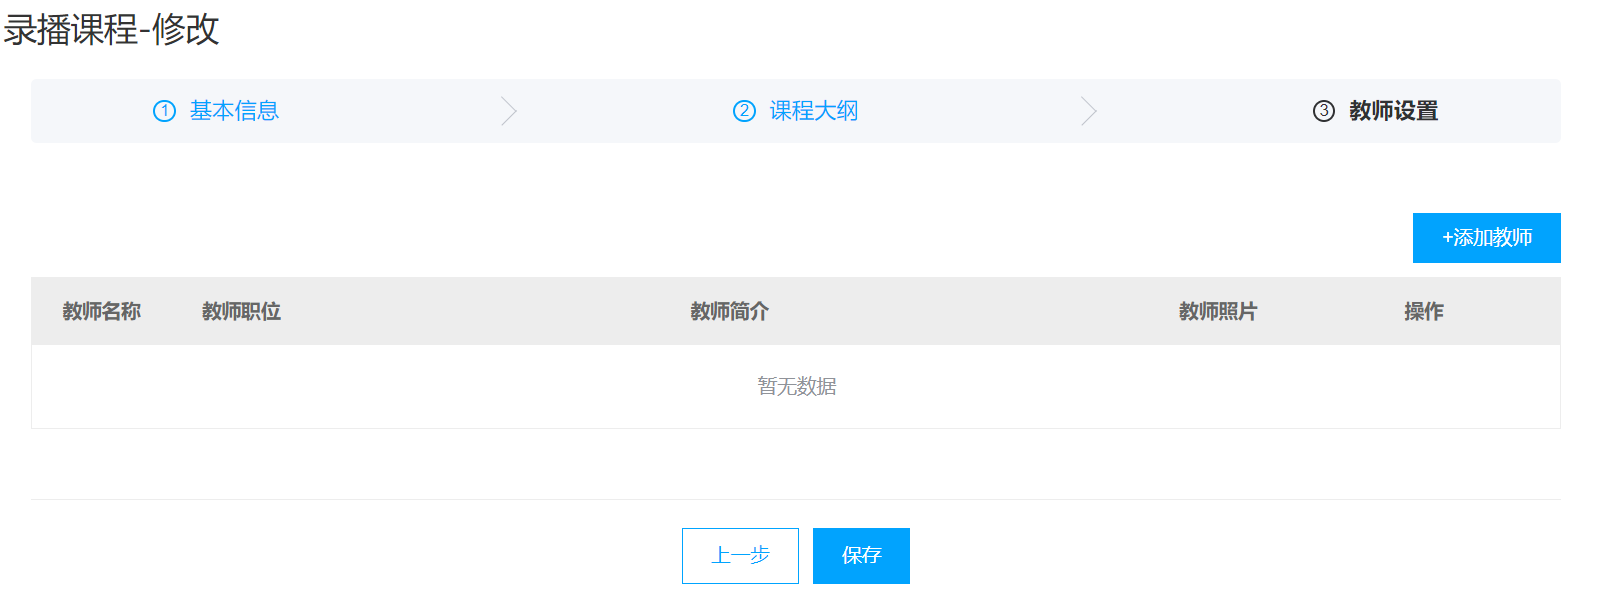

day04 源码已有 `CourseTeacher` PO：

| Java 字段 | 类型 | 含义 |
|---|---|---|
| `id` | Long | 师资记录主键，`IdType.AUTO` |
| `courseId` | Long | 所属课程 |
| `teacherName` | String | 教师名称 |
| `position` | String | 职位 |
| `introduction` | String | 简介 |
| `photograph` | String | 照片地址，本日不实现照片上传 |
| `createDate` | LocalDateTime | 创建时间，有 `FieldFill.INSERT` 声明 |

同一位“王老师”可以出现在多门课中，每门课对应不同的师资记录 ID。删除课程 75 中的王老师，只删除该课程的记录，不应按姓名批量删除其他课程师资，更不应删除教师账户。

已有 `CourseTeacherMapper` 提供 MyBatis-Plus 基础操作，但内容业务模块没有完成师资 Controller / Service。代码生成器目录中的同名模板不能当作可用业务接口。


## 17. 师资 DTO：只接收本次允许编辑的字段

为什么不直接把页面 JSON 原样绑定到 PO 再保存？因为 PO 包含自增 ID、课程关系和创建时间，客户端可能带来不应覆盖的数据。

下面是**补充 DTO**，名称、职位设为必填；简介是否必填和字段长度上限，应与实际页面、数据库列长度及产品要求确认。

```java
@Data
public class AddCourseTeacherDto {
    @NotNull(message = "课程ID不能为空")
    private Long courseId;

    @NotBlank(message = "教师姓名不能为空")
    private String teacherName;

    @NotBlank(message = "教师职位不能为空")
    private String position;

    private String introduction;
}

@Data
@EqualsAndHashCode(callSuper = true)
public class EditCourseTeacherDto extends AddCourseTeacherDto {
    @NotNull(message = "师资记录ID不能为空")
    private Long id;
}
```

当前课程使用 Java 8、Spring Boot 2.3.7.RELEASE，校验注解来自 `javax.validation.constraints`，Controller 使用 `@Valid` 触发请求体校验。Lombok 的 `@Data`、`@EqualsAndHashCode` 及业务 DTO 均需正常导入。

本篇 DTO 不把 `createDate` 暴露为可编辑字段，也暂不编辑 `photograph`。若实际前端传这两个额外字段，应约定忽略还是报错；不要依赖未确认的反序列化配置。请求示例只发送支持的字段，返回对象仍保留照片和创建时间。

新增后的记录 ID 从数据库生成，修改则必须携带原 ID；继承 DTO 不自动校验课程归属，这一项仍由 Service 完成。


## 18. 查询师资：按课程过滤并检查机构

讲义请求为 `GET /courseTeacher/list/75`，内容服务完整路径为 `/content/courseTeacher/list/75`。返回的是数组，不是课程分页接口的 `PageResult`。

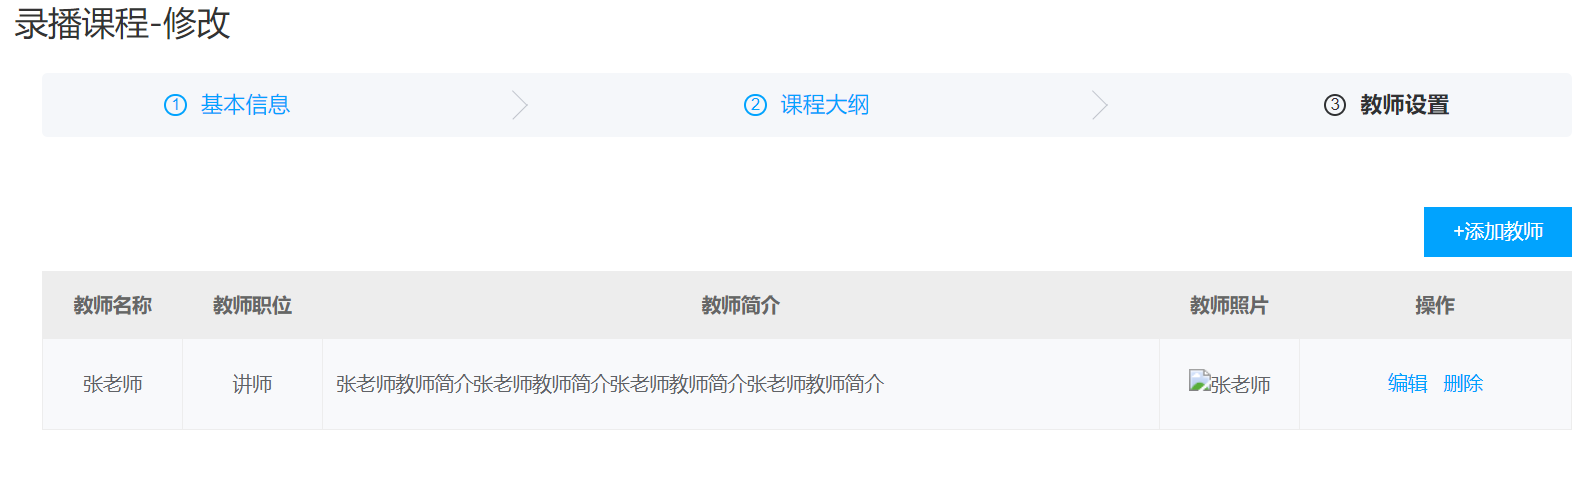

**补充 Service 方法**：

```java
public List<CourseTeacher> listTeachers(Long companyId, Long courseId) {
    requireOwnedCourse(companyId, courseId);
    return courseTeacherMapper.selectList(
        new QueryWrapper<CourseTeacher>()
            .eq("course_id", courseId)
            .orderByAsc("id")
    );
}
```

讲义特别强调添加 / 删除只能操作本机构课程；这里把归属检查补充到查询与修改，形成一致的访问规则。`orderByAsc("id")` 是本篇的稳定展示策略，讲义没有额外定义教师排序字段。

讲义响应示例：

```json
[
  {
    "id": 23,
    "courseId": 75,
    "teacherName": "张老师",
    "position": "讲师",
    "introduction": "张老师教师简介",
    "photograph": null,
    "createDate": null
  }
]
```

这里的 `createDate: null` 是原示例，不代表后端应主动清空时间。实际保存时间后，查询应返回保存值。课程存在且无教师时返回 `[]`；课程不存在或无权访问时，按统一错误契约返回异常，不能把两种情况混成“空列表”。


## 19. 新增教师：先确认课程，再生成记录

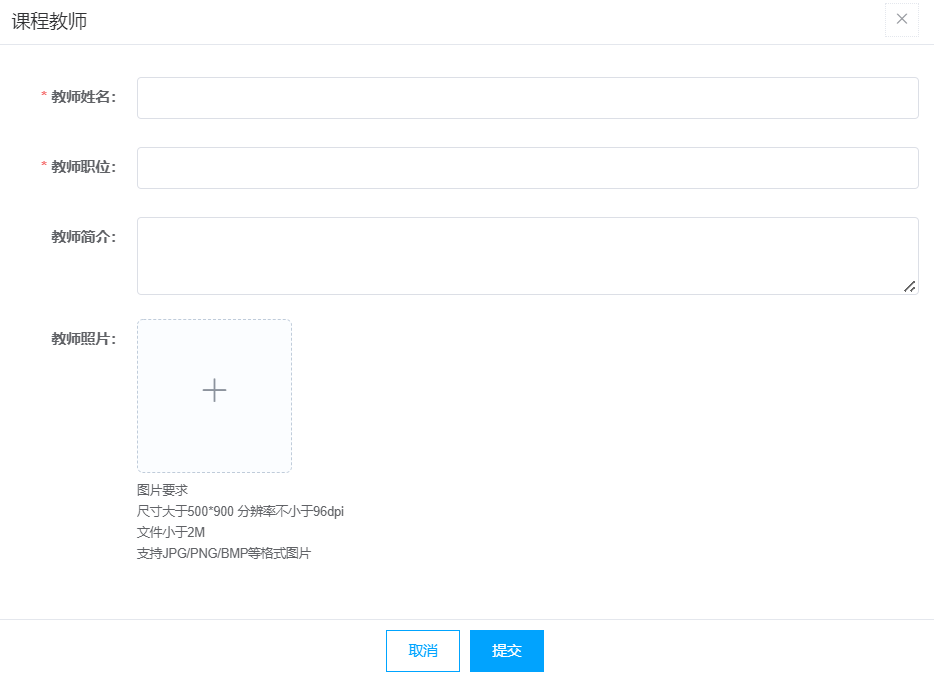

新增请求携带课程、姓名、职位和简介。照片上传不在本日任务内，不必为了完成师资管理先搭建文件上传服务。

**补充 Service 实现**：

```java
@Transactional(rollbackFor = Exception.class)
public CourseTeacher addTeacher(Long companyId, AddCourseTeacherDto dto) {
    requireOwnedCourse(companyId, dto.getCourseId());
    CourseTeacher teacher = new CourseTeacher();
    teacher.setCourseId(dto.getCourseId());
    teacher.setTeacherName(dto.getTeacherName());
    teacher.setPosition(dto.getPosition());
    teacher.setIntroduction(dto.getIntroduction());
    teacher.setCreateDate(LocalDateTime.now());
    if (courseTeacherMapper.insert(teacher) != 1) {
        throw new XueChengPlusException("新增教师失败");
    }
    return courseTeacherMapper.selectById(teacher.getId());
}
```

`IdType.AUTO` 使插入成功后主键回填到 `teacher.id`，因此返回值应含数据库生成的 ID。重新查询返回数据库保存后的对象，避免把未经落库验证的请求体直接作为成功响应。

**源码事实**：PO 上的 `FieldFill.INSERT` 只是自动填充声明，已核对的业务源码没有 `MetaObjectHandler` 实现。本片段显式设置 `LocalDateTime.now()`，不假定注解会自己生成时间；团队也可以统一实现填充器。

如果课程删除与师资新增可能同时发生，需要在新增前与删除操作协调锁定课程并重查归属 / 存在性。单条 INSERT 成功不能保证它没有挂到刚被另一个事务删除的课程上。


## 20. 修改教师：记录归属与创建时间必须保留

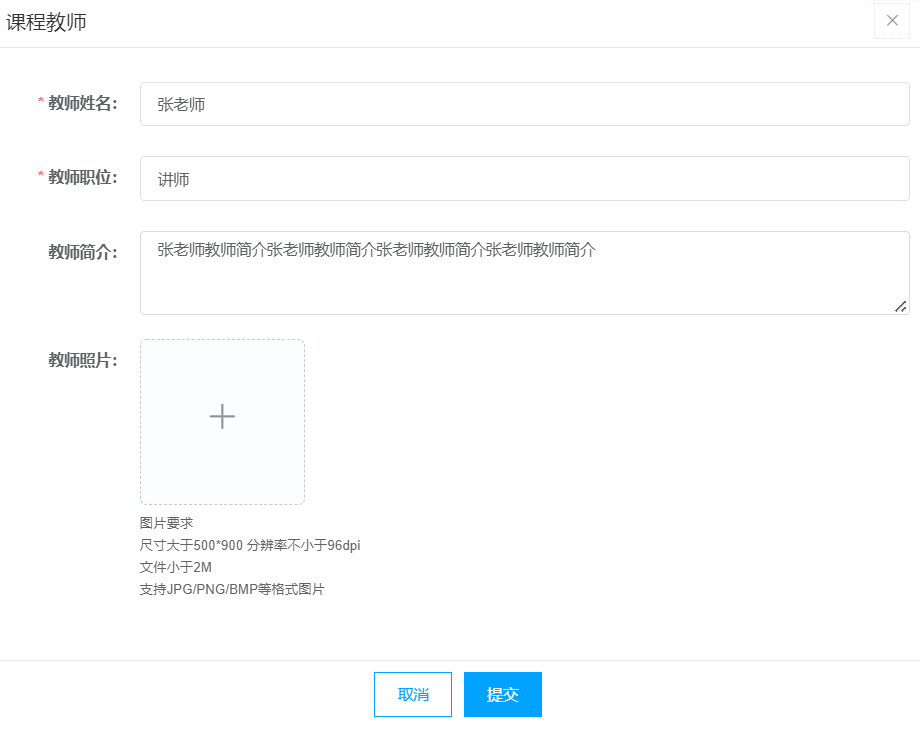

修改请求既有 `id` 又有 `courseId`。需要确认这两个值对应同一条关系，否则用户可能把其他课程的教师 ID 配上自己课程的 ID，借此更新不属于自己的记录。

**补充实现片段**：

```java
@Transactional(rollbackFor = Exception.class)
public CourseTeacher updateTeacher(Long companyId, EditCourseTeacherDto dto) {
    requireOwnedCourse(companyId, dto.getCourseId());
    CourseTeacher old = courseTeacherMapper.selectById(dto.getId());
    if (old == null || !dto.getCourseId().equals(old.getCourseId())) {
        throw new XueChengPlusException("师资记录不存在或不属于当前课程");
    }

    courseTeacherMapper.update(null,
        new UpdateWrapper<CourseTeacher>()
            .eq("id", old.getId())
            .eq("course_id", old.getCourseId())
            .set("teacher_name", dto.getTeacherName())
            .set("position", dto.getPosition())
            .set("introduction", dto.getIntroduction())
    );
    CourseTeacher saved = courseTeacherMapper.selectById(old.getId());
    if (saved == null || !old.getCourseId().equals(saved.getCourseId())) {
        throw new XueChengPlusException("师资记录已变化，请刷新后重试");
    }
    return saved;
}
```

这里只设置姓名、职位、简介，不修改 `id`、`course_id`、`create_date` 或已有 `photograph`。这样编辑时页面传 `createDate: null` 不会把创建时间清掉，也不会把师资悄悄转移到另一门课。

没有修改任何字段时，数据库驱动的更新行数语义可能影响返回值；不能一律把“影响 0 行”解释为记录不存在。本教学片段重新查询确认记录，但严格的并发修改仍应使用行锁或版本字段来识别覆盖，重新查询不能替代并发控制。

师资页已核对的 `handleEdit` 只是设置 `teacherData = data` 并打开弹窗，保存实现位于未取得的弹窗 / API 文件。本篇按 day04 DOCX 的 PUT 契约编写，不将 PDF 中的 POST 当作已验证的实际前端行为。


## 21. 删除教师：课程 ID 与记录 ID 一起限定

讲义删除示例中的 `75` 是课程 ID，`26` 是 `course_teacher` 表主键。实战教师页也确实调用 `deleteTeacher(this.courseBaseId, data.id)`，证明页面同时提供这两个参数。

本篇校正后的接口：`DELETE /content/courseTeacher/course/{courseId}/{teacherId}`。

**补充 Service 方法**：

```java
@Transactional(rollbackFor = Exception.class)
public void deleteTeacher(Long companyId, Long courseId, Long teacherId) {
    requireOwnedCourse(companyId, courseId);
    if (teacherId == null) {
        throw new XueChengPlusException("师资记录ID不能为空");
    }
    CourseTeacher teacher = courseTeacherMapper.selectById(teacherId);
    if (teacher == null || !courseId.equals(teacher.getCourseId())) {
        throw new XueChengPlusException("师资记录不存在或不属于当前课程");
    }
    int deleted = courseTeacherMapper.delete(
        new QueryWrapper<CourseTeacher>()
            .eq("course_id", courseId)
            .eq("id", teacherId)
    );
    if (deleted != 1) {
        throw new XueChengPlusException("删除教师失败");
    }
}
```

正例：机构 A 拥有课程 75，师资 26 也属于 75，删除成功。反例：机构 A 拥有课程 75，但师资 26 属于课程 80，即使第一个课程检查通过，第二个关系检查仍应拒绝。

先查关系再按两列删除，让检查和实际写入范围保持一致。当前示例对不存在记录返回业务错误；团队也可以规定重复删除返回成功，但必须区分普通重复请求与课程 / 机构关系不匹配。


## 22. 师资 Controller：四个方法对应四种操作

补充 `CourseTeacherService`，约定 `listTeachers`、`addTeacher`、`updateTeacher`、`deleteTeacher` 四个方法，并按前文实现。下面的 Controller 是**拟新增业务类**，不是代码生成器中的模板。

```java
@RestController
@RequestMapping("/courseTeacher")
public class CourseTeacherController {
    @Autowired
    private CourseTeacherService courseTeacherService;

    @GetMapping("/list/{courseId}")
    public List<CourseTeacher> list(
            @PathVariable("courseId") Long courseId) {
        return courseTeacherService.listTeachers(1232141425L, courseId);
    }

    @PostMapping
    public CourseTeacher add(
            @RequestBody @Valid AddCourseTeacherDto dto) {
        return courseTeacherService.addTeacher(1232141425L, dto);
    }

    @PutMapping
    public CourseTeacher update(
            @RequestBody @Valid EditCourseTeacherDto dto) {
        return courseTeacherService.updateTeacher(1232141425L, dto);
    }

    @DeleteMapping("/course/{courseId}/{teacherId}")
    public void delete(
            @PathVariable("courseId") Long courseId,
            @PathVariable("teacherId") Long teacherId) {
        courseTeacherService.deleteTeacher(1232141425L, courseId, teacherId);
    }
}
```

需要导入 Spring MVC 注解、`Autowired`、`javax.validation.Valid`、`List` 与 DTO / PO / Service；实现类添加 `@Service` 并注入 Mapper。完整入口是 `context-path /content + 类路径 /courseTeacher + 方法路径`。

POST 负责新建，PUT 负责修改，避免两个成员在同一个 POST 路径上分别定义新增、修改造成重复映射。若配套前端实际使用 PDF 中的单 POST 保存模式，应统一契约后调整，而不是只改后端或只改 HTTP 测试文件。

路径参数写明名称，减少对编译参数名设置的依赖。HTTP 路径里的 `courseTeacher` 也保持统一大小写。


## 23. 师资 HTTP 测试与验收矩阵

测试顺序是新增 → 查询 → 用返回 ID 修改 → 再查询 → 删除 → 再查询。下例 `24` 只是示例 ID，必须换成新增响应中的实际值。

```http
### 新增教师
POST http://localhost:63040/content/courseTeacher
Content-Type: application/json

{
  "courseId": 75,
  "teacherName": "王老师",
  "position": "讲师",
  "introduction": "负责Java与项目实战教学"
}

### 按课程查询教师
GET http://localhost:63040/content/courseTeacher/list/75

### 修改新增响应中的师资记录
PUT http://localhost:63040/content/courseTeacher
Content-Type: application/json

{
  "id": 24,
  "courseId": 75,
  "teacherName": "王老师",
  "position": "高级讲师",
  "introduction": "负责内容管理模块实战"
}

### 删除指定课程下的记录
DELETE http://localhost:63040/content/courseTeacher/course/75/24

### 再查询确认删除结果
GET http://localhost:63040/content/courseTeacher/list/75
```

| 用例 | 预期结果 |
|---|---|
| 为本机构课程新增教师 | 返回生成的记录 ID，查询能看到 |
| 姓名 / 职位为空或纯空格 | DTO 校验失败，不插入 |
| 修改姓名、职位、简介 | ID、课程归属、创建时间保留 |
| 为别的机构的课程新增 / 查询 / 修改 / 删除 | 后端拒绝，数据库保持原状 |
| 课程 75 与课程 80 的教师 ID 混搭 | 拒绝，不更新 / 删除其他课程的记录 |
| 删除成功后刷新 | 仅目标师资记录消失 |
| 没有教师的正常课程 | 查询返回 `[]`，页面显示暂无数据 |
| 表单不上传照片 | 四个师资接口仍可完成 |

不同课程出现同名教师，不属于本日明确禁止的情况。不要自行添加“教师姓名全库唯一”规则，再把合理的跨课程师资记录当作 Bug。


## 24. 删除整门课程：清理一个业务聚合

课程基本信息、营销、计划、计划媒资和师资共同组成当前内容管理聚合。只删除 `course_base` 会留下查不到课程却仍存在的关联数据。

**讲义要求**：课程审核状态为未提交才能删除。文本列出基本信息、营销信息、计划、师资；第 9.5.3 节验收还明确包含课程计划关联信息，所以 **`teachplan_media` 不能漏掉**。

| 表 | 关联条件 | 清理顺序 |
|---|---|---|
| `teachplan_media` | `course_id = 目标课程` | 先清理计划媒资关系 |
| `teachplan` | `course_id = 目标课程` | 再清理章、小节 |
| `course_teacher` | `course_id = 目标课程` | 清理本课程师资 |
| `course_market` | `id = 目标课程 ID` | 清理营销；原工程营销 ID 与课程 ID 共用 |
| `course_base` | `id = 目标课程 ID` | 最后删除课程主记录 |

若实际数据库给 `teachplan.parentid` 建了自引用外键，还应按“小节 → 章”处理计划删除，具体以表结构为准。不能只凭 PO 注释推断数据库一定没有约束。

整课程删除与单节点删除的业务不同：前者通过课程级归属和状态检查后，批量清理所有内容关系；后者必须拒绝“有孩子的章”。不能简单循环调用“删除有子章会失败”的单节点接口完成整课程删除。

本日不处理已发布快照、学习记录、订单或支付数据的跨服务清理；起始实战聚焦内容库中的未提交课程。后续进入发布、选课、支付后，需要重新设计删除 / 下架边界。


## 25. 删除课程的 Controller 与事务实现

在 `CourseBaseInfoService` 补充 `deleteCourse(Long companyId, Long courseId)`，由对应实现类完成。Controller 只调用一次 Service，不能自己逐表调用多个方法并希望天然整体回滚。

**补充实现片段**：

```java
@DeleteMapping("/course/{courseId}")
public void deleteCourse(@PathVariable("courseId") Long courseId) {
    courseBaseInfoService.deleteCourse(1232141425L, courseId);
}
```

```java
@Transactional(rollbackFor = Exception.class)
public void deleteCourse(Long companyId, Long courseId) {
    CourseBase course = requireOwnedCourse(companyId, courseId);
    requireDraft(course);

    teachplanMediaMapper.delete(
        new QueryWrapper<TeachplanMedia>().eq("course_id", courseId)
    );
    teachplanMapper.delete(
        new QueryWrapper<Teachplan>().eq("course_id", courseId)
    );
    courseTeacherMapper.delete(
        new QueryWrapper<CourseTeacher>().eq("course_id", courseId)
    );
    courseMarketMapper.deleteById(courseId);

    int deleted = courseBaseMapper.delete(
        new QueryWrapper<CourseBase>()
            .eq("id", courseId)
            .eq("company_id", companyId)
            .eq("audit_status", "202002")
    );
    if (deleted != 1) {
        throw new XueChengPlusException("课程状态已变化或删除失败");
    }
}
```

关联表没有记录时，删除影响 0 行通常正常。例如课程刚建好还没添加计划，不应因此无法删除。主记录则预期删除 1 行；最后一次条件删除没成功，应抛异常回滚前面的清理。

末条 SQL 再限定 `company_id` 与 `audit_status`，让写入条件与此前检查一致。片段假设数据关系正确、当前内容库中相关表能在同一个事务下删除；严格并发与实际外键适配还需补全。

任何一个 Mapper 抛数据库异常，都应让整个业务失败。不要逐表用 `try/catch` 忽略异常，也不要把部分清理成功作为“删除成功”返回。


## 26. 删除课程的状态检查、并发与数据库验收

前端 `course-list.vue` 的删除按钮判断：

```text
auditStatus != '202002' 时禁用删除按钮
```

这能减少误操作，但直接构造 HTTP 请求仍可绕过页面。因此后端必须自己检查机构和未提交状态；不能因为按钮灰了就省去 Service 检查。

```http
### 仅使用自己准备的未提交测试课程
DELETE http://localhost:63040/content/course/87
```

删除后应逐表确认，而不是只看课程列表消失。下面是**验收查询示例，未执行**；`@course_id` 需由测试环境设置为目标测试课程。

```sql
SELECT COUNT(*) AS base_count
FROM course_base WHERE id = @course_id;

SELECT COUNT(*) AS market_count
FROM course_market WHERE id = @course_id;

SELECT COUNT(*) AS plan_count
FROM teachplan WHERE course_id = @course_id;

SELECT COUNT(*) AS plan_media_count
FROM teachplan_media WHERE course_id = @course_id;

SELECT COUNT(*) AS teacher_count
FROM course_teacher WHERE course_id = @course_id;
```

| 验收场景 | 预期 |
|---|---|
| 本机构未提交课程，有完整计划和师资 | 5 类记录均清理，其他课程保留 |
| 未提交课程，无营销 / 计划 / 师资记录 | 允许按约定删除，关联 0 行不视为失败 |
| 别的机构课程 | 拒绝，所有表不变 |
| 已提交课程 | 拒绝，所有表不变 |
| 中途数据库异常 | 全部回滚，主记录与关联恢复 |
| 同一课程重复删除 | 按统一不存在 / 幂等契约处理 |

**补充并发方案**：整课程删除、提交审核、新增计划、绑定媒资和新增师资应协调课程级修改，先锁课程行，在锁内重查状态和关系。第 25 节的末条条件删除可以发现一些状态变化，但不能独自防止并发插入关联记录。

如果历史脏数据中 `teachplan_media.course_id` 与实际计划所属课程不一致，简单按课程清理会遗漏或误清关系。正常写入应保证两者一致，异常数据先核对修复，不能把“跨课程补删”隐藏在普通接口中。


## 27. 前后端联调：从真实请求到真实保存结果

读实战页面代码后，可把问题沿完整链路定位：

`页面按钮 → @/api/courses → 请求 URL / 方法 / body → Controller → Service → Mapper / 数据库 → 刷新查询 → 展示`

| 现象 | 优先核对 |
|---|---|
| 404 | `/api` 代理是否正确、`/content` 是否重复、`courseTeacher` 是否拼错 |
| 405 | 实际前端发送 POST 还是 PUT；与教师修改的资料差异对照 |
| 服务启动时报映射冲突 | 不同成员是否注册了相同方法与路径 |
| 删除后刷新又出现 | 删除请求是否成功，事务是否回滚，是否删错 ID |
| 排序数据库已变但页面不变 | 计划树查询是否按 `orderby`，是否重新请求 |
| 空章突然不显示 | 前一天计划查询是否还使用会过滤空章的 INNER JOIN |
| 教师页面为空 | 返回是否为数组，课程 ID 是否正确，页面初始化是否触发查询 |
| 教师弹窗提交不生效 | 核对完整工程的 dialog 与 API；仅三个补丁不能证明保存逻辑 |

实战计划页面依赖 `teachplanMedia.mediaFilename` 展示文件名，解绑时还使用 `teachplanMedia.teachplanId`、`mediaId`。如果查询对象缺这些字段，前端无法正确展示 / 解绑；应检查第三篇的 DTO 与 Mapper 映射补全，而不是在删除接口临时猜参数。

补丁中的多个操作使用空 `catch (error) {}`。它可能捕获用户取消，也可能吞掉请求异常；需结合全局请求拦截器确认是否已有错误提示。不能仅因空 catch 就断言整个前端不会提示，更不能在失败后用成功 toast 掩盖结果。

请求成功后的 `getList()` 是再查询服务器数据。若列表只是本地重新排序，刷新后恢复原序，说明保存链路没有完成。验收应至少包含一次重新加载页面。


## 28. 综合实战演示与 Bug 记录

讲义要求小组选一门资料完整的课程，包含详细介绍和大纲，演示新增、修改、排序和删除。可选“Java 入门”作为自己的测试数据，设置两个章、每章两个小节，并添加两条师资记录。

| 步骤 | 演示内容 | 应留下的证据 |
|---|---|---|
| 1 | 添加课程与营销信息 | 课程 ID、请求响应、列表与回显 |
| 2 | 新增章、小节，编辑名称与试看 | 计划树和关系数据；空章可见 |
| 3 | 添加、查询、编辑教师 | 返回的师资 ID，创建时间与归属保留 |
| 4 | 大章 / 小节上下移动 | 移动前后序号、首尾不变、其他父节点不变 |
| 5 | 删除有小节的章 | 明确失败，数据保留 |
| 6 | 删除小节，再删除空章 | 节点与媒资关联正确清理 |
| 7 | 删除一个教师 | 只删除本课程目标记录 |
| 8 | 删除未提交课程 | 5 类关联查询结果及其他课程保留 |
| 9 | 交叉验证异常路径 | 机构不匹配、状态不符、ID 混搭与事务回滚 |

建议 Bug 文档按下表记录，便于另一位成员复现：

| 字段 | 示例 |
|---|---|
| 标题 | 排序空洞导致上移无效 |
| 环境 / 代码版本 | 分支与提交标识、内容服务和前端版本 |
| 前置数据 | 同章小节 ID 与 `orderby` 分别为 1、3、8 |
| 操作 / 请求 | 点击序号 3 的小节上移，记录实际 URL 与方法 |
| 预期 | 与序号 1 的小节交换 |
| 实际 | 返回成功，但顺序未变 |
| 证据 | 请求响应、页面与数据库记录 |
| 修复与回归 | 改为查实际前驱；再测首尾、其他章、重复序号 |

回滚验证应在测试环境通过可控失败复现，不能拿真实用户课程尝试破坏。完成后由同伴在合并工程上复测，证明接口与其他人的代码一起工作。


## 29. 原始材料、起始源码与补充方案对照

本篇以 day04 讲义第 9 节和 11 页实战 PDF 为任务依据，以后端起始源码及三个前端补丁为实现事实依据。二者不能混写成“资料已给出完整实现”。

| 项目 | 已确认的事实 | 本篇补充 / 校正 |
|---|---|---|
| 本日接口 | PDF 明确 8 个接口 | 完整路径、公共校验、实现顺序 |
| 后端包 | 与 day03 包相同，业务接口尚待开发 | 删除计划、排序、师资 CRUD、删除课程片段 |
| 错误响应 | `RestErrorResponse` 只有 `errMessage` | 区分讲义 `errCode=120409` 与实际错误模型 |
| 教师修改 | DOCX 写 PUT，PDF 写 POST | 本篇用 PUT，真实前端仍需联调核对 |
| 教师删除 | 原文 `/ourseTeacher` 漏字母 c | 校正为 `/courseTeacher/course/{courseId}/{teacherId}` |
| 前端补丁 | 3 个页面，明确调用名、ID 参数、刷新与按钮状态 | 不声称已检查未下载的 API / 弹窗 |
| 排序 | 原文要求与同级邻居交换 | 限定课程和父节点，处理空洞、重复值与并发 |
| 创建时间 | 师资 PO 声明自动填充，未发现填充器 | 显式赋值或另行实现统一填充 |
| 整课程删除 | 文字列四类信息，验收含计划关联 | 将 `teachplan_media` 纳入事务清理 |
| 团队流程 | 仓库、分工、交叉测试、Bug 文档、汇报 | 避免重复映射，明确公共代码负责人 |

起始工程版本延续第三篇：Java `1.8`，Spring Boot `2.3.7.RELEASE`，Spring Cloud `Hoxton.SR9`，Spring Cloud Alibaba `2.2.6.RELEASE`，MyBatis-Plus `3.4.1`，MySQL Connector `8.0.30`，Swagger Starter `1.9.0.RELEASE`。本笔记不更换框架版本。

**复现时仍需完成**：将片段放入正确模块，补全 Service 声明、依赖注入和 imports；统一真实前端契约；检查实际表约束与字典；编译项目；执行接口、页面和数据库测试。Notebook 格式 / 示例静态检查通过，不等于课程服务已经运行通过。


## 30. 面试提示

**面试提示**：

| 问题 | 回答要点 |
|---|---|
| 第四天为什么是“项目实战”？ | 给定需求与初始工程，自主分析 8 个接口，协作开发、交叉测试与完整演示 |
| 删除章和删除小节有何不同？ | 有孩子的章拒绝删；空章允许；小节删除要清理计划媒资绑定 |
| 删除媒资关联会删除视频文件吗？ | 不会，关系与共享文件生命周期不同 |
| 为什么前端禁用按钮仍要后端校验？ | 可绕过页面直接请求；机构与审核状态必须由后端确认 |
| 同级计划范围怎样定义？ | 同课程、同父节点；grade 相同不足以证明是兄弟 |
| 上移为什么不用 orderby-1？ | 存在删除后的空洞，应找实际前驱 |
| 交换排序值为什么要事务？ | 两条更新是一个业务动作，部分成功会造成错误序号 |
| 加事务能解决所有排序并发吗？ | 不能；需协调锁、条件更新或版本控制，并覆盖新增 / 删除路径 |
| 有排序唯一约束时如何交换？ | 直接交换可能冲突；在互斥保护下使用合法未占用临时值等策略，并实际验证数据库行为 |
| 师资记录 ID 是教师账号 ID 吗？ | 是 course_teacher 主键，一条记录属于一门课 |
| 教师修改为什么同时检查课程与记录？ | 防止课程 ID 与其他课程师资 ID 混搭；只允许更新规定字段 |
| 删除课程要清哪些表？ | 计划媒资、计划、师资、营销、基本信息，同一事务处理当前内容聚合 |
| 为什么删除关联影响 0 行可以正常？ | 课程可能尚无这类关联；主记录删除与并发冲突则按契约检查 |
| 如何证明实战功能完成？ | HTTP、页面刷新、数据库关系、异常路径、回滚与合并工程的交叉测试一起验收 |

回答时可以讲一个具体过程：“先校验课程归属和草稿状态，拒绝删除有小节的章；删除小节时先清绑定；排序找同父节点的实际邻居并原子交换；师资校验记录与课程；最后在一个事务中删除整门草稿课程”。再说明资料差异和并发边界，就能把接口、数据关系与验证串起来。
